# Chapitre 18 - Exercices 18.6 à 18.10

- 18.6 : l'analyse discriminante régularisée calculée en dimension $N$ ;
- 18.7 : moindres carrés quand $p\gg N$ et solution de norme minimale ;
- 18.8 : directions d'« empilement » des données (*data piling*) ;
- 18.9 : empilement maximal contre hyperplan séparateur optimal (SVM) ;
- 18.10 : limite de l'analyse discriminante ridge et empilement maximal.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl import ch18_grande_dimension as g

## Exercice 18.6 : Analyse discriminante régularisée en dimension $N$

**Énoncé (reformulé).** Montrer comment le théorème de la section 18.3.5 (calculs en
dimension $N$ via la SVD) s'applique à l'analyse discriminante régularisée
(section 4.3.1 et éq. (18.9)) :
$\hat\Sigma(\gamma) = \gamma\hat\Sigma + (1-\gamma)\operatorname{diag}(\hat\Sigma)$.

**Rappels.** La LDA (section 4.3) classe $x$ selon le maximum des fonctions
discriminantes
$$\delta_k(x) = x^T\Sigma^{-1}\mu_k - \tfrac12\mu_k^T\Sigma^{-1}\mu_k + \log\pi_k ,$$
où $\mu_k$ est le centroïde de la classe $k$ et $\Sigma$ la covariance intra-classe
commune, estimée par $\hat\Sigma = \frac1{N-K}\sum_i(x_i - \hat\mu_{g_i})(x_i-\hat\mu_{g_i})^T$.
La RDA remplace $\hat\Sigma$ par $\hat\Sigma(\gamma)$, inversible pour $\gamma < 1$.
Inverser directement une matrice $p\times p$ coûte $O(p^3)$.

**Solution.**

*Étape 1 : standardisation.* Soit $\hat D = \operatorname{diag}(\hat\Sigma) = \operatorname{diag}(s_1^2,\dots,s_p^2)$.
Posons $\tilde x = \hat D^{-1/2}x$ (chaque variable divisée par $s_j$),
$\tilde\mu_k = \hat D^{-1/2}\hat\mu_k$ et $\tilde\Sigma = \hat D^{-1/2}\hat\Sigma\hat D^{-1/2}$
(une matrice de corrélation intra-classe). Alors
$\hat\Sigma(\gamma) = \hat D^{1/2}\big(\gamma\tilde\Sigma + (1-\gamma)I\big)\hat D^{1/2}$ et
$$x^T\hat\Sigma(\gamma)^{-1}\hat\mu_k = \tilde x^T\big(\gamma\tilde\Sigma + (1-\gamma)I\big)^{-1}\tilde\mu_k ,$$
et de même pour le terme quadratique : sur les données standardisées, la RDA est une
LDA avec une covariance « ridge » $\gamma\tilde\Sigma + (1-\gamma)I$ - une pénalité
quadratique isotrope.

*Étape 2 : tout vit dans l'espace des lignes.* Soit $\tilde{\mathbf X} = \mathbf R\mathbf V^T$
la SVD réduite des données standardisées ($\mathbf V$ : $p\times N$, $\mathbf V^T\mathbf V = I_N$)
et $r_i = \mathbf V^T\tilde x_i$, de sorte que $\tilde x_i = \mathbf Vr_i$. Alors :

- les centroïdes sont des moyennes de lignes : $\tilde\mu_k = \mathbf V\bar r_k$ ;
- les lignes centrées par classe aussi : $\tilde x_i - \tilde\mu_{g_i} = \mathbf V(r_i - \bar r_{g_i})$ ;
- donc $\tilde\Sigma = \mathbf V\mathbf S\mathbf V^T$ avec
  $\mathbf S = \frac1{N-K}\sum_i(r_i-\bar r_{g_i})(r_i-\bar r_{g_i})^T$ ($N\times N$).

*Étape 3 : inversion en dimension $N$.* Notons $\mathbf A = \gamma\mathbf S + (1-\gamma)I_N$.
Pour tout $a\in\mathbb R^N$,
$$\big(\gamma\mathbf V\mathbf S\mathbf V^T + (1-\gamma)I_p\big)\mathbf V\mathbf A^{-1}a = \mathbf V(\gamma\mathbf S + (1-\gamma)I)\mathbf A^{-1}a = \mathbf Va,$$
(on a utilisé $\mathbf V^T\mathbf V = I_N$), donc
$\big(\gamma\tilde\Sigma + (1-\gamma)I\big)^{-1}\mathbf Va = \mathbf V\mathbf A^{-1}a$.
Pour un point test, $\tilde x_0 = \mathbf Vr_0 + \tilde x_\perp$ avec
$r_0 = \mathbf V^T\tilde x_0$ et $\mathbf V^T\tilde x_\perp = 0$ ; d'où
$$\delta_k(x_0) = r_0^T\mathbf A^{-1}\bar r_k - \tfrac12\bar r_k^T\mathbf A^{-1}\bar r_k + \log\pi_k .$$
C'est une **LDA ordinaire sur les $N$ coordonnées $r_i$**, avec la covariance
régularisée $\mathbf A$. Le coût passe de $O(p^3)$ à $O(N^2p)$. $\square$

> **Remarque.** C'est exactement l'esprit du théorème (18.16)-(18.17) : la
> régularisation est invariante par rotation (après standardisation), et la composante
> des points hors de l'espace des données ne change pas le classement.

In [2]:
def rda_reduced(Xtr, ytr, Xte, gammas):
    """RDA (18.9) calculée en dimension N ; retourne les classes prédites pour chaque gamma."""
    classes, counts, means, s = g.class_statistics(Xtr, ytr)
    N, K = len(ytr), len(classes)
    R, V = g.svd_reduce(Xtr / s)
    inv = np.searchsorted(classes, ytr)
    rbar = np.array([R[inv == k].mean(0) for k in range(K)])
    W = R - rbar[inv]
    S = W.T @ W / (N - K)
    r0 = (Xte / s) @ V
    logpi = np.log(counts / N)
    preds = []
    for gam in gammas:
        A = gam * S + (1 - gam) * np.eye(R.shape[1])
        Ainv_r = np.linalg.solve(A, rbar.T)                    # (N, K)
        delta = r0 @ Ainv_r - 0.5 * np.sum(rbar.T * Ainv_r, 0) + logpi
        preds.append(classes[np.argmax(delta, 1)])
    return preds


def rda_direct(Xtr, ytr, Xte, gamma):
    """RDA par inversion explicite de la matrice p x p (pour vérification)."""
    classes, counts, means, s = g.class_statistics(Xtr, ytr)
    N, K = len(ytr), len(classes)
    W = Xtr - means[np.searchsorted(classes, ytr)]
    Sig = W.T @ W / (N - K)
    Sg = gamma * Sig + (1 - gamma) * np.diag(np.diag(Sig))
    B = np.linalg.solve(Sg, means.T)
    delta = Xte @ B - 0.5 * np.sum(means.T * B, 0) + np.log(counts / N)
    return classes[np.argmax(delta, 1)], delta

**Vérification** sur NCI (8 classes, découpage des cours), d'abord sur 1000 gènes où
l'on peut encore inverser la matrice $1000\times1000$.

In [3]:
X_all, lab_all = datasets.load_nci()
types, counts = np.unique(lab_all, return_counts=True)
keep = np.isin(lab_all, types[counts >= 5])
X, lab = X_all[keep], lab_all[keep]
split = g.stratified_folds(lab, 3, np.random.RandomState(0))
te, tr = split == 0, split != 0
Xtr, ytr, Xte, yte = X[tr], lab[tr], X[te], lab[te]

sub = slice(0, 1000)
for gam in [0.0, 0.3, 0.9]:
    p_dir, _ = rda_direct(Xtr[:, sub], ytr, Xte[:, sub], gam)
    p_red = rda_reduced(Xtr[:, sub], ytr, Xte[:, sub], [gam])[0]
    print(f"gamma = {gam} : prédictions identiques ? {np.all(p_dir == p_red)}")

gamma = 0.0 : prédictions identiques ? True
gamma = 0.3 : prédictions identiques ? True
gamma = 0.9 : prédictions identiques ? True


On peut aussi comparer les **scores** eux-mêmes, au terme $-\frac12\tilde x_0^T(\dots)^{-1}\tilde x_0$
près (commun à toutes les classes). Passons maintenant aux 6830 gènes, uniquement en
dimension réduite.

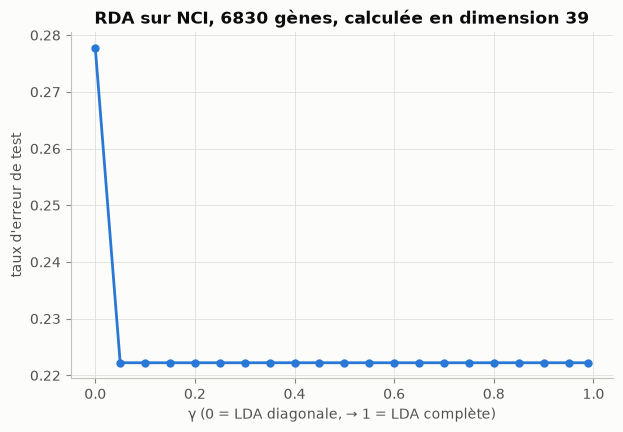

LDA diagonale (s0 = 0) via les centroïdes réduits : 0.278  ; RDA gamma = 0 : 0.278


In [4]:
gammas = np.r_[0.0, np.linspace(0.05, 0.95, 19), 0.99]
preds = rda_reduced(Xtr, ytr, Xte, gammas)
err = [np.mean(p != yte) for p in preds]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(gammas, err, "o-", color=BLUE)
ax.set_xlabel("γ (0 = LDA diagonale, → 1 = LDA complète)")
ax.set_ylabel("taux d'erreur de test")
ax.set_title("RDA sur NCI, 6830 gènes, calculée en dimension 39")
plt.show()
print("LDA diagonale (s0 = 0) via les centroïdes réduits :",
      np.mean(g.NearestShrunkenCentroids(0.0, s0=0.0).fit(Xtr, ytr).predict(Xte) != yte).round(3),
      " ; RDA gamma = 0 :", round(err[0], 3))

Pour $\gamma = 0$, on retrouve la LDA diagonale (même erreur que les centroïdes réduits
sans rétrécissement ni $s_0$). Dès que $\gamma > 0$, l'erreur tombe à 4 erreurs sur 18
et reste constante sur toute la plage : comme dans le tableau 18.1 du livre (où toutes
les valeurs $\gamma\in(0.002, 0.55)$ donnaient la même erreur), le résultat est peu
sensible au choix de $\gamma$.

> **À retenir.** Après standardisation, la RDA est une LDA à covariance « ridge » ;
> son calcul se ramène à une LDA sur les $N$ coordonnées de la SVD.

## Exercice 18.7 : Moindres carrés quand $p\gg N$

**Énoncé (reformulé).** On suppose $p\gg N$ et $\operatorname{rang}(\mathbf X) = N$. Soit
$\mathbf X = \mathbf U\mathbf D\mathbf V^T = \mathbf R\mathbf V^T$ la SVD, avec
$\mathbf R$ ($N\times N$) inversible et $\mathbf V$ ($p\times N$) à colonnes orthonormées.

(a) Montrer qu'il existe une infinité de solutions des moindres carrés, toutes à
résidus nuls.
(b) Montrer que l'estimateur ridge s'écrit $\hat\beta_\lambda = \mathbf V(\mathbf R^T\mathbf R+\lambda I)^{-1}\mathbf R^Ty$ (éq. (18.56)).
(c) Montrer que pour $\lambda = 0$, la solution $\hat\beta_0 = \mathbf V\mathbf D^{-1}\mathbf U^Ty$
a des résidus nuls et qu'elle est l'unique solution de norme euclidienne minimale
parmi les solutions à résidus nuls.

**Solution.**

**(a)** $\mathbf X$ est $N\times p$ de rang $N$ : son image est tout $\mathbb R^N$, donc
l'équation $\mathbf X\beta = y$ a au moins une solution $\beta^*$ ; pour elle, la somme
des carrés des résidus vaut $0$, le minimum possible : c'est une solution des moindres
carrés. Par le théorème du rang, $\dim\ker\mathbf X = p - N > 0$ ; pour tout
$n\in\ker\mathbf X$, $\mathbf X(\beta^* + n) = y$ : l'ensemble des solutions est le
sous-espace affine $\beta^* + \ker\mathbf X$, infini. Réciproquement, toute solution des
moindres carrés atteint le minimum $0$, donc a des résidus nuls.

**(b)** C'est exactement l'exercice 18.4 (formule (18.15)).

**(c)** *Limite $\lambda\to0$.* $\mathbf R = \mathbf U\mathbf D$ est inversible, donc
$\mathbf R^T\mathbf R$ aussi, et par continuité de l'inverse
$$\hat\beta_\lambda\to\mathbf V(\mathbf R^T\mathbf R)^{-1}\mathbf R^Ty = \mathbf V\mathbf R^{-1}(\mathbf R^T)^{-1}\mathbf R^Ty = \mathbf V\mathbf R^{-1}y = \mathbf V\mathbf D^{-1}\mathbf U^Ty = \hat\beta_0 ,$$
car $\mathbf R^{-1} = \mathbf D^{-1}\mathbf U^{-1} = \mathbf D^{-1}\mathbf U^T$ ($\mathbf U$ orthogonale).

*Résidus nuls.* $\mathbf X\hat\beta_0 = \mathbf U\mathbf D\mathbf V^T\mathbf V\mathbf D^{-1}\mathbf U^Ty = \mathbf U\mathbf U^Ty = y$.

*Norme minimale.* $\ker\mathbf X = \{n : \mathbf R\mathbf V^Tn = 0\} = \{n:\mathbf V^Tn = 0\}$
($\mathbf R$ inversible) est l'orthogonal de $\operatorname{Im}\mathbf V$. Toute solution
à résidus nuls s'écrit $\beta = \hat\beta_0 + n$ avec $n\in\ker\mathbf X$ ; or
$\hat\beta_0 = \mathbf V(\cdot)\in\operatorname{Im}\mathbf V\perp n$, donc par Pythagore
$$\|\beta\|^2 = \|\hat\beta_0\|^2 + \|n\|^2\ \ge\ \|\hat\beta_0\|^2,$$
avec égalité si et seulement si $n = 0$. $\hat\beta_0$ est l'unique solution de norme
minimale : c'est $\mathbf X^+y$, avec $\mathbf X^+$ la pseudo-inverse de Moore-Penrose. $\square$

In [5]:
rng = np.random.RandomState(7)
N7, p7 = 20, 100
X7, y7 = rng.randn(N7, p7), rng.randn(N7)
U7, d7, Vt7 = np.linalg.svd(X7, full_matrices=False)
beta0 = Vt7.T @ ((U7.T @ y7) / d7)
print("résidus de beta0          :", np.abs(X7 @ beta0 - y7).max())
print("beta0 = pinv(X) y ?       :", np.allclose(beta0, np.linalg.pinv(X7) @ y7))
print("beta0 = lstsq(X, y) ?     :", np.allclose(beta0, np.linalg.lstsq(X7, y7, rcond=None)[0]))

résidus de beta0          : 4.551914400963142e-15
beta0 = pinv(X) y ?       : True
beta0 = lstsq(X, y) ?     : True


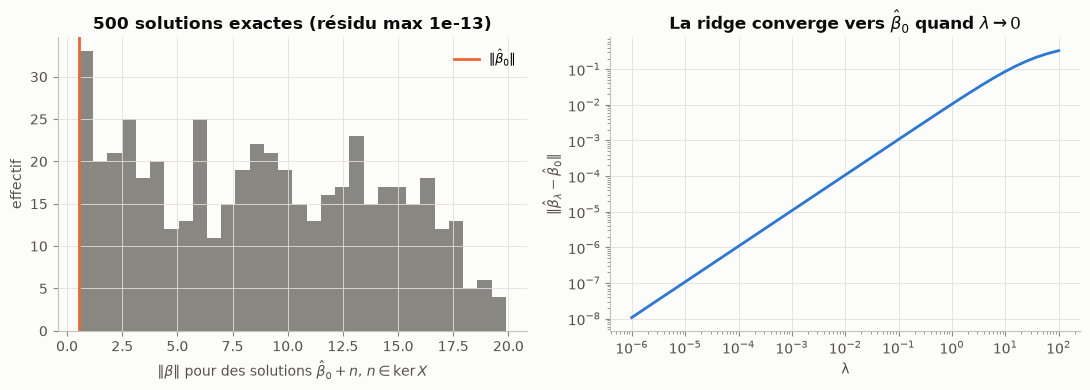

In [6]:
P_null = np.eye(p7) - Vt7.T @ Vt7                # projecteur sur ker X
norms, resids = [], []
for _ in range(500):
    n = P_null @ rng.randn(p7) * rng.uniform(0, 2)
    norms.append(np.linalg.norm(beta0 + n))
    resids.append(np.abs(X7 @ (beta0 + n) - y7).max())
lam_grid = np.logspace(-6, 2, 40)
B = g.ridge_svd(X7, y7, lam_grid)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(norms, bins=30, color=GRAY)
axes[0].axvline(np.linalg.norm(beta0), color=ORANGE, lw=2, label=r"$\|\hat\beta_0\|$")
axes[0].set_xlabel(r"$\|\beta\|$ pour des solutions $\hat\beta_0 + n$, $n \in \ker X$")
axes[0].set_ylabel("effectif")
axes[0].set_title(f"500 solutions exactes (résidu max {max(resids):.0e})")
axes[0].legend()
axes[1].loglog(lam_grid, np.linalg.norm(B - beta0, axis=1), color=BLUE)
axes[1].set_xlabel("λ")
axes[1].set_ylabel(r"$\|\hat\beta_\lambda - \hat\beta_0\|$")
axes[1].set_title(r"La ridge converge vers $\hat\beta_0$ quand $\lambda \to 0$")
plt.tight_layout()
plt.show()

> **À retenir.** Quand $p > N$, les moindres carrés interpolent et ne sont pas uniques ;
> la limite $\lambda\to0$ de la ridge sélectionne la solution de **norme minimale**
> $\mathbf X^+y = \mathbf V\mathbf D^{-1}\mathbf U^Ty$, qui vit dans l'espace des lignes.

## Exercice 18.8 : Empilement des données (*data piling*)

**Énoncé (reformulé).** L'exercice 4.2 montre que la LDA à deux classes s'obtient par
régression linéaire d'une réponse $y\in\{-1,+1\}$ : $\hat\beta^Tx$ est, à une
transformation affine près, le score discriminant. On suppose $p\gg N$.

(a) Pour le modèle $f(x) = \alpha + \beta^Tx$ ajusté à $y\in\{-1,+1\}$, montrer (via
l'exercice 18.7) qu'il existe une infinité de directions $\hat\beta$ sur lesquelles les
données se projettent en **exactement deux points**, un par classe (directions
d'empilement, Ahn et Marron, 2005).
(b) Montrer que la distance entre les deux points projetés est $2/\|\hat\beta\|$ ; ces
directions définissent donc des hyperplans séparateurs de marge $2/\|\hat\beta\|$.
(c) Montrer qu'il existe une unique direction d'empilement **maximal**, où cette
distance est la plus grande, donnée par $\hat\beta_0 = \mathbf X^-y$ (pseudo-inverse,
$\mathbf X = \mathbf U\mathbf D\mathbf V^T$).

**Mise en place.** Avec un intercept, on centre les colonnes : $\mathbf X_c = (I-\mathbf M)\mathbf X$,
$\mathbf M = \frac1N\mathbf 1\mathbf 1^T$. Pour des données génériques avec $p\ge N$,
$\mathbf X_c$ est de rang $N-1$ et son image est exactement $\mathbf 1^\perp$ (les vecteurs
de somme nulle) : elle est contenue dans $\mathbf 1^\perp$ (colonnes centrées) et de
même dimension.

**(a)** On cherche $(\alpha,\beta)$ avec $\alpha\mathbf 1 + \mathbf X_c\beta = y$
(résidus nuls). En multipliant par $\mathbf 1^T$ : $N\alpha = \mathbf 1^Ty$, donc
$\alpha = \bar y$, puis $\mathbf X_c\beta = y - \bar y\mathbf 1\in\mathbf 1^\perp = \operatorname{Im}\mathbf X_c$ :
ce système a des solutions, et (exercice 18.7(a)) une infinité, de la forme
$\beta + n$, $n\in\ker\mathbf X_c$, de dimension $p - N + 1$. Pour chacune,
$\beta^T(x_i - \bar x) = y_i - \bar y\in\{1-\bar y, -1-\bar y\}$ : **tous les points d'une
même classe se projettent au même point** sur la droite dirigée par $\beta$.

**(b)** Sur la droite dirigée par le vecteur unitaire $\beta/\|\beta\|$, la coordonnée
de $x_i$ est $\beta^Tx_i/\|\beta\|$. Pour $x_i$ dans la classe $+1$ et $x_{i'}$ dans la
classe $-1$ :
$$\frac{\beta^T(x_i - x_{i'})}{\|\beta\|} = \frac{(y_i - \bar y) - (y_{i'}-\bar y)}{\|\beta\|} = \frac{2}{\|\beta\|}.$$
L'hyperplan $\{x : \beta^T(x-\bar x) = -\bar y\}$, à mi-chemin, sépare donc parfaitement
les classes, chaque classe étant à distance $1/\|\beta\|$ de lui : marge $2/\|\beta\|$.

**(c)** Maximiser $2/\|\beta\|$ revient à minimiser $\|\beta\|$ parmi les solutions de
$\mathbf X_c\beta = y-\bar y\mathbf 1$. D'après l'exercice 18.7(c) (dont la preuve par
Pythagore vaut pour une matrice de rang quelconque), il existe une **unique** solution
de norme minimale, $\hat\beta_0 = \mathbf X_c^+(y-\bar y\mathbf 1) = \mathbf X_c^+y$
(car $\mathbf X_c^+\mathbf 1 = 0$, $\mathbf 1$ étant orthogonal à l'image de
$\mathbf X_c$). C'est la direction d'empilement maximal. $\square$

In [7]:
rng = np.random.RandomState(8)
N8, p8 = 30, 500
y8 = np.r_[np.ones(15), -np.ones(15)]
X8 = rng.randn(N8, p8)
X8[:, :20] += 0.8 * y8[:, None]
xbar8 = X8.mean(0)
X8c = X8 - xbar8
# rcond : on annule la valeur singulière (numériquement) nulle créée par le centrage
beta_mdp = np.linalg.pinv(X8c, rcond=1e-10) @ y8                  # empilement maximal
U8, d8, Vt8 = np.linalg.svd(X8c, full_matrices=False)
n8 = rng.randn(p8)
n8 -= Vt8.T @ (Vt8 @ n8)                              # n dans ker X_c
beta_other = beta_mdp + 0.05 * n8                     # une autre direction d'empilement
beta_md = X8c[y8 > 0].mean(0) - X8c[y8 < 0].mean(0)   # différence des moyennes
X8t = rng.randn(200, p8)
y8t = np.r_[np.ones(100), -np.ones(100)]
X8t[:, :20] += 0.8 * y8t[:, None]

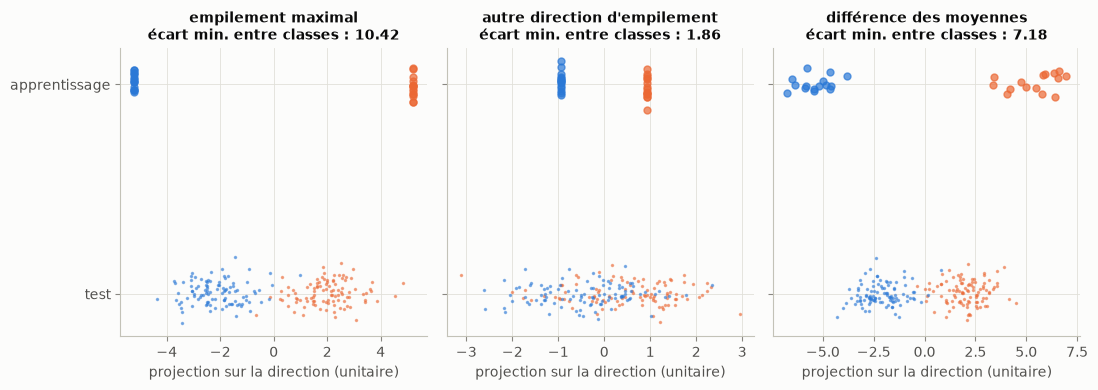

2/||beta_mdp|| = 10.420463846117865  ; 2/||beta_autre|| = 1.8622592112385943


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharey=True)
for ax, b, title in [(axes[0], beta_mdp, "empilement maximal"),
                     (axes[1], beta_other, "autre direction d'empilement"),
                     (axes[2], beta_md, "différence des moyennes")]:
    u = b / np.linalg.norm(b)
    ptr = X8c @ u
    pte = (X8t - xbar8) @ u
    for cls, c in [(1, ORANGE), (-1, BLUE)]:
        ax.plot(ptr[y8 == cls], np.full((y8 == cls).sum(), 1.0) + 0.05 * rng.randn((y8 == cls).sum()),
                "o", color=c, ms=5, alpha=0.7)
        ax.plot(pte[y8t == cls], np.zeros((y8t == cls).sum()) + 0.05 * rng.randn((y8t == cls).sum()),
                ".", color=c, ms=3, alpha=0.5)
    gap = ptr[y8 > 0].min() - ptr[y8 < 0].max()
    ax.set_title(f"{title}\nécart min. entre classes : {gap:.2f}", fontsize=10)
    ax.set_xlabel("projection sur la direction (unitaire)")
axes[0].set_yticks([0, 1], ["test", "apprentissage"])
plt.tight_layout()
plt.show()
print("2/||beta_mdp|| =", 2 / np.linalg.norm(beta_mdp), " ; 2/||beta_autre|| =", 2 / np.linalg.norm(beta_other))

Sur les deux premières directions, les 30 points d'apprentissage s'empilent en **deux
points** (orange : classe $+1$, bleu : classe $-1$), séparés de $2/\|\hat\beta\|$ ; la
direction d'empilement maximal donne le plus grand écart. Mais les **points test**
(en bas) se projettent de façon très dispersée : l'empilement est un artefact de la
grande dimension, pas une séparation réelle. La différence des moyennes n'empile pas
les données d'apprentissage.

> **À retenir.** Quand $p\ge N$, il existe une infinité de directions sur lesquelles
> chaque classe d'apprentissage se réduit à un point ; parmi elles, une seule maximise
> l'écart : $\hat\beta_0 = \mathbf X_c^+y$.

## Exercice 18.9 : Empilement maximal contre hyperplan séparateur optimal

**Énoncé (reformulé).** Comparer qualitativement la direction d'empilement maximal de
l'exercice 18.8 et la direction de l'hyperplan séparateur optimal (section 4.5.2).
Laquelle donne la plus grande marge, et pourquoi ? Illustrer par une petite simulation.

**Solution.** Avec la normalisation habituelle, l'hyperplan séparateur optimal (SVM à
marge dure, section 4.5.2) résout
$$\min_{\beta_0,\beta}\ \|\beta\|\quad\text{sous}\quad y_i(\beta_0 + x_i^T\beta)\ \ge\ 1,\ i = 1,\dots,N,$$
et sa marge (distance entre les deux hyperplans $\beta_0 + x^T\beta = \pm1$) vaut
$2/\|\hat\beta\|$. L'empilement maximal résout le **même** problème avec des contraintes
d'**égalité** $y_i(\beta_0 + x_i^T\beta) = 1$ (avec $y_i = \pm 1$, cela équivaut à
$\beta_0 + x_i^T\beta = y_i$, exercice 18.8).

L'ensemble admissible de l'empilement est **inclus** dans celui du SVM ; le minimum de
$\|\beta\|$ sur un ensemble plus grand est plus petit : $\|\hat\beta_{\mathrm{SVM}}\|\le\|\hat\beta_{\mathrm{MDP}}\|$,
donc
$$\text{marge}_{\mathrm{SVM}} = \frac2{\|\hat\beta_{\mathrm{SVM}}\|}\ \ge\ \frac2{\|\hat\beta_{\mathrm{MDP}}\|} = \text{marge}_{\mathrm{MDP}} .$$
**Le SVM donne toujours la marge la plus large.** Il y a égalité quand toutes les
contraintes du SVM sont actives, c'est-à-dire quand **tous** les points sont vecteurs
supports : alors le SVM empile lui aussi les données.

*Qualitativement* : la direction d'empilement est déterminée par **tous** les points
(une régression), alors que le SVM ne dépend que des points proches de la frontière.
Quand $p\gg N$, presque tous les points deviennent vecteurs supports et les deux
directions se rapprochent.

**Simulation.** Nous implémentons le SVM à marge dure par son problème **dual**
(section 12.2) :
$\max_\alpha\sum_i\alpha_i - \frac12\sum_{i,i'}\alpha_i\alpha_{i'}y_iy_{i'}x_i^Tx_{i'}$
sous $\alpha_i\ge0$, $\sum_i\alpha_iy_i = 0$ ; puis $\hat\beta = \sum_i\hat\alpha_iy_ix_i$
et $\hat\beta_0$ est obtenu sur les vecteurs supports ($\hat\alpha_i > 0$).

In [9]:
def hard_margin_svm(X, y):
    """SVM à marge dure par le dual (SLSQP) ; retourne beta0, beta, alpha."""
    n = len(y)
    Q = (y[:, None] * X) @ (y[:, None] * X).T
    fun = lambda a: 0.5 * a @ Q @ a - a.sum()
    jac = lambda a: Q @ a - 1
    res = optimize.minimize(fun, np.zeros(n), jac=jac, method="SLSQP",
                            bounds=[(0, None)] * n,
                            constraints=[{"type": "eq", "fun": lambda a: a @ y, "jac": lambda a: y}],
                            options={"maxiter": 1000, "ftol": 1e-14})
    a = res.x
    beta = (a * y) @ X
    sv = a > 1e-6 * a.max()
    beta0 = np.mean(y[sv] - X[sv] @ beta)
    return beta0, beta, a


def max_data_piling(X, y):
    xbar = X.mean(0)
    beta = np.linalg.pinv(X - xbar, rcond=1e-10) @ y
    return y.mean() - xbar @ beta, beta


rng = np.random.RandomState(9)
Xs = rng.randn(40, 200)
ys = np.r_[np.ones(20), -np.ones(20)]
Xs[:, :10] += 0.7 * ys[:, None]
b0_svm, b_svm, a_svm = hard_margin_svm(Xs, ys)
b0_mdp, b_mdp = max_data_piling(Xs, ys)
from sklearn.svm import SVC
sk = SVC(kernel="linear", C=1e10).fit(Xs, ys)
print("min y_i f(x_i) : SVM =", np.min(ys * (b0_svm + Xs @ b_svm)).round(4),
      " ; empilement =", np.min(ys * (b0_mdp + Xs @ b_mdp)).round(4))
print("écart à scikit-learn (SVC, C très grand) :", np.abs(b_svm - sk.coef_[0]).max().round(6))
print(f"marge SVM = {2 / np.linalg.norm(b_svm):.4f}  >=  marge empilement = {2 / np.linalg.norm(b_mdp):.4f}")
print("vecteurs supports :", np.sum(a_svm > 1e-6 * a_svm.max()), "sur", len(ys))

min y_i f(x_i) : SVM = 1.0  ; empilement = 1.0
écart à scikit-learn (SVC, C très grand) : 2.4e-05
marge SVM = 5.6913  >=  marge empilement = 5.6851
vecteurs supports : 37 sur 40


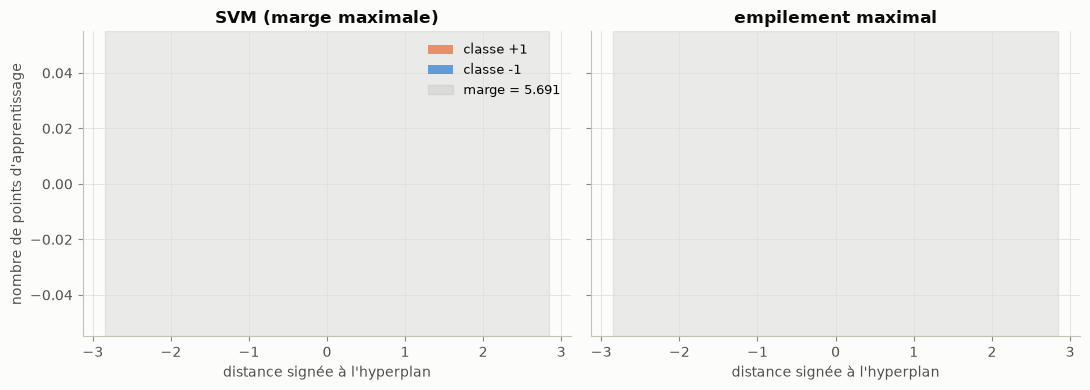

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (b0, b), title in [(axes[0], (b0_svm, b_svm), "SVM (marge maximale)"),
                           (axes[1], (b0_mdp, b_mdp), "empilement maximal")]:
    f = (b0 + Xs @ b) / np.linalg.norm(b)
    m = 1 / np.linalg.norm(b)
    for cls, c in [(1, ORANGE), (-1, BLUE)]:
        ax.hist(f[ys == cls], bins=np.linspace(-0.6, 0.6, 61), color=c, alpha=0.7,
                label=f"classe {cls:+d}")
    ax.axvspan(-m, m, color=GRAY, alpha=0.15, label=f"marge = {2 * m:.3f}")
    ax.set_xlabel("distance signée à l'hyperplan")
    ax.set_title(title)
axes[0].set_ylabel("nombre de points d'apprentissage")
axes[0].legend()
plt.tight_layout()
plt.show()

Le SVM a une marge un peu plus large ; certains points sont au-delà de la marge (non
supports), alors que l'empilement place tous les points exactement sur les bords.

**Influence de $p$** ($N = 40$, 30 répétitions) : rapport des marges, proportion de
vecteurs supports et erreur de test.

In [11]:
rng = np.random.RandomState(10)
p_list = [40, 80, 200, 500, 1500]
ratio, frac_sv, err_svm, err_mdp = [], [], [], []
for p in p_list:
    r, f, e1, e2 = [], [], [], []
    for _ in range(30):
        X = rng.randn(40, p)
        X[:, :10] += 0.7 * ys[:, None]
        Xt = rng.randn(400, p)
        yt = np.r_[np.ones(200), -np.ones(200)]
        Xt[:, :10] += 0.7 * yt[:, None]
        b0s, bs, a = hard_margin_svm(X, ys)
        b0m, bm = max_data_piling(X, ys)
        r.append(np.linalg.norm(bm) / np.linalg.norm(bs))
        f.append(np.mean(a > 1e-6 * a.max()))
        e1.append(np.mean(np.sign(b0s + Xt @ bs) != yt))
        e2.append(np.mean(np.sign(b0m + Xt @ bm) != yt))
    ratio.append(np.mean(r)); frac_sv.append(np.mean(f))
    err_svm.append(np.mean(e1)); err_mdp.append(np.mean(e2))

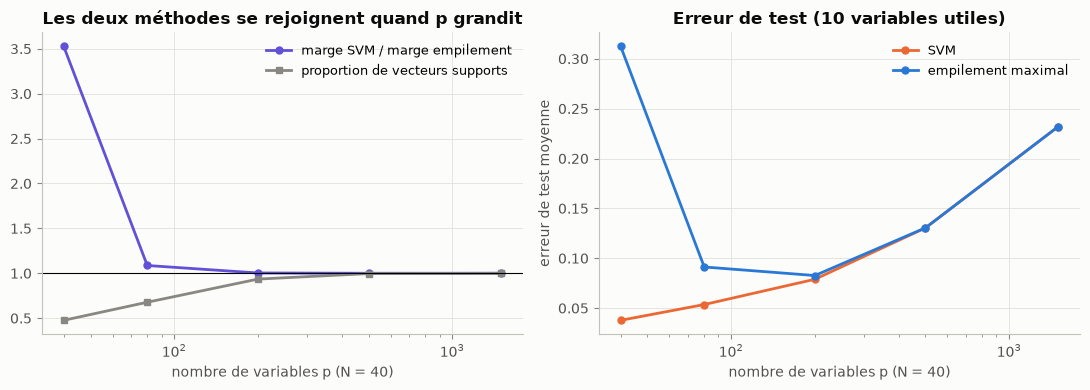

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogx(p_list, ratio, "o-", color=COLORS[6], label="marge SVM / marge empilement")
axes[0].semilogx(p_list, frac_sv, "s-", color=GRAY, label="proportion de vecteurs supports")
axes[0].axhline(1, color="k", lw=0.8)
axes[0].set_xlabel("nombre de variables p (N = 40)")
axes[0].set_title("Les deux méthodes se rejoignent quand p grandit")
axes[0].legend()
axes[1].semilogx(p_list, err_svm, "o-", color=ORANGE, label="SVM")
axes[1].semilogx(p_list, err_mdp, "o-", color=BLUE, label="empilement maximal")
axes[1].set_xlabel("nombre de variables p (N = 40)")
axes[1].set_ylabel("erreur de test moyenne")
axes[1].set_title("Erreur de test (10 variables utiles)")
axes[1].legend()
plt.tight_layout()
plt.show()

Le rapport des marges est toujours $\ge 1$ et tend vers 1 : quand $p$ augmente, la
proportion de vecteurs supports tend vers 1 et le SVM devient lui-même une direction
d'empilement. Pour $p$ proche de $N$, l'empilement maximal (qui interpole des données
bruitées) généralise nettement moins bien que le SVM ; l'écart disparaît quand $p\gg N$.
(L'erreur des deux méthodes augmente ensuite avec $p$ : seules 10 variables sont
utiles, les autres ajoutent du bruit.)

> **À retenir.** Le SVM maximise la marge sous des contraintes d'inégalité,
> l'empilement maximal sous des contraintes d'égalité : la marge du SVM est toujours
> au moins aussi grande, avec égalité si tous les points sont vecteurs supports.

## Exercice 18.10 : Limite de l'analyse discriminante ridge

**Énoncé (reformulé).** Quand $p\gg N$, la LDA est dégénérée car la matrice de
covariance intra-classe $\mathbf W$ est singulière. Une version de la RDA remplace
$\mathbf W$ par $\mathbf W + \lambda I$, d'où la fonction discriminante
$\delta_\lambda(x) = x^T(\mathbf W+\lambda I)^{-1}(\bar x_1 - \bar x_{-1})$. Montrer que
$\delta_0(x) = \lim_{\lambda\downarrow0}\delta_\lambda(x)$ correspond à la direction
d'empilement maximal de l'exercice 18.8.

**Précision.** Le vecteur $d = \bar x_1 - \bar x_{-1}$ n'est en général pas dans l'image de
$\mathbf W$, de sorte que $(\mathbf W+\lambda I)^{-1}d$ **explose** comme $1/\lambda$. Ce qui
a une limite, c'est la **direction** (ou de façon équivalente
$\lambda(\mathbf W+\lambda I)^{-1}d$) ; une fonction discriminante n'étant définie qu'à
un facteur positif près, c'est le sens de l'énoncé.

**Solution.** Notons $\mathbf W = \sum_i(x_i - \bar x_{g_i})(x_i-\bar x_{g_i})^T$ (le facteur
de normalisation ne change pas la direction), $\mathcal W = \operatorname{Im}\mathbf W$ et
$P$ le projecteur orthogonal sur $\mathcal W$. $\mathbf W$ est symétrique positive : dans
une base orthonormée de vecteurs propres, $\mathbf W = \sum_{\ell}w_\ell e_\ell e_\ell^T$
avec $w_\ell > 0$ pour $e_\ell\in\mathcal W$.

*Étape 1 : la limite.* Décomposons $d = Pd + d_\perp$ avec $d_\perp = (I-P)d\perp\mathcal W$.
Alors $(\mathbf W+\lambda I)^{-1}d_\perp = d_\perp/\lambda$ (car $\mathbf Wd_\perp = 0$) et
$(\mathbf W+\lambda I)^{-1}Pd = \sum_{w_\ell>0}\frac{e_\ell^Td}{w_\ell+\lambda}e_\ell$ reste borné. Donc
$$\lambda(\mathbf W+\lambda I)^{-1}d\ \xrightarrow[\lambda\downarrow0]{}\ d_\perp = (I-P)\,d .$$

*Étape 2 : $d_\perp$ est une direction d'empilement.* Chaque $x_i$ s'écrit
$x_i = \bar x_{g_i} + w_i$ avec $w_i = x_i - \bar x_{g_i}\in\mathcal W$ (les colonnes de
$\mathbf W$ sont des combinaisons des $w_i$, et réciproquement $\mathcal W$ est engendré par
les $w_i$). Comme $d_\perp\perp\mathcal W$ : $d_\perp^Tx_i = d_\perp^T\bar x_{g_i}$, qui ne prend
que **deux valeurs** (une par classe) : les données s'empilent.

*Étape 3 : c'est l'empilement maximal.* Notons $\mathcal L$ l'espace engendré par les
lignes centrées $x_i - \bar x$ (dimension $N-1$ pour des données génériques). On a
$\mathcal W\subset\mathcal L$ et $d\in\mathcal L$, donc $d_\perp\in\mathcal L$. Or
$\dim\mathcal W = N-2$ (deux contraintes : $\sum_{i\in C_k}w_i = 0$ pour chaque classe),
donc $\mathcal L\cap\mathcal W^\perp$ est une **droite**. Toute direction d'empilement
$\beta\in\mathcal L$ vérifie $\beta^Tw_i = 0$ pour tout $i$ (voir la remarque
ci-dessous), donc $\beta\perp\mathcal W$ : elle est sur cette droite. Enfin
$\hat\beta_0 = \mathbf X_c^+y$ appartient à $\mathcal L$ (une pseudo-inverse renvoie dans
l'espace des lignes) et est une direction d'empilement (exercice 18.8). Donc
$d_\perp$ et $\hat\beta_0$ sont colinéaires : $\delta_0$ est (à un facteur près) le score
sur la direction d'empilement maximal. $\square$

> **Remarque.** Le passage « $\beta^Tw_i = 0$ » vient de ce que, pour une direction
> d'empilement, $\beta^Tx_i$ est constant dans chaque classe, donc égal à sa moyenne
> $\beta^T\bar x_{g_i}$ : $\beta^T(x_i - \bar x_{g_i}) = 0$.

In [13]:
rng = np.random.RandomState(11)
N10, p10 = 30, 300
y10 = np.r_[np.ones(12), -np.ones(18)]
X10 = rng.randn(N10, p10)
X10[:, :15] += 0.6 * y10[:, None]
m_pos, m_neg = X10[y10 > 0].mean(0), X10[y10 < 0].mean(0)
Wc = np.where(y10[:, None] > 0, X10 - m_pos, X10 - m_neg)
Wmat = Wc.T @ Wc
d10 = m_pos - m_neg
beta_mdp10 = np.linalg.pinv(X10 - X10.mean(0), rcond=1e-10) @ y10
lam_grid = np.logspace(-6, 4, 40)
cosines, norms = [], []
for lam in lam_grid:
    v = np.linalg.solve(Wmat + lam * np.eye(p10), d10)
    cosines.append(v @ beta_mdp10 / (np.linalg.norm(v) * np.linalg.norm(beta_mdp10)))
    norms.append(np.linalg.norm(v))
print("rang de W :", np.linalg.matrix_rank(Wmat), "(N - 2 =", N10 - 2, ")")

rang de W : 28 (N - 2 = 28 )


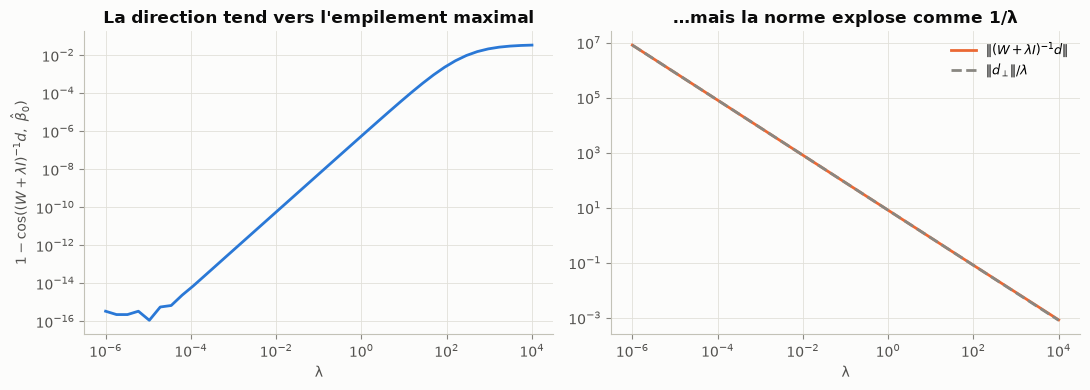

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogx(lam_grid, 1 - np.array(cosines), color=BLUE)
axes[0].set_yscale("log")
axes[0].set_xlabel("λ")
axes[0].set_ylabel(r"$1 - \cos((W+\lambda I)^{-1}d,\ \hat\beta_0)$")
axes[0].set_title("La direction tend vers l'empilement maximal")
axes[1].loglog(lam_grid, norms, color=ORANGE, label=r"$\|(W+\lambda I)^{-1}d\|$")
axes[1].loglog(lam_grid, np.linalg.norm(d10 - np.linalg.pinv(Wmat, rcond=1e-10) @ Wmat @ d10) / lam_grid,
               "--", color=GRAY, label=r"$\|d_\perp\| / \lambda$")
axes[1].set_xlabel("λ")
axes[1].set_title("…mais la norme explose comme 1/λ")
axes[1].legend()
plt.tight_layout()
plt.show()

In [15]:
v_small = np.linalg.solve(Wmat + 1e-8 * np.eye(p10), d10)
proj = X10 @ v_small / np.linalg.norm(v_small)
print("projections sur la direction limite, classe +1 :", np.round(np.ptp(proj[y10 > 0]), 8), "(étendue)")
print("projections sur la direction limite, classe -1 :", np.round(np.ptp(proj[y10 < 0]), 8), "(étendue)")

projections sur la direction limite, classe +1 : 0.0 (étendue)
projections sur la direction limite, classe -1 : 0.0 (étendue)


Pour $\lambda$ petit, la direction de la RDA coïncide avec $\hat\beta_0$ et les données
d'apprentissage s'empilent (étendue nulle dans chaque classe).

> **À retenir.** Quand $p\gg N$, la LDA « ridge » à régularisation évanescente se
> comporte comme la direction d'empilement maximal : elle sépare parfaitement les
> données d'apprentissage en deux points, ce qui est un signe de sur-ajustement ; il
> faut garder $\lambda$ (ou $\gamma$) loin de la limite.